# Seminar 05: SLIM, EASE and Factorization Machines

Learn item-to-item reconstruction with **SLIM** and **EASE**, then generalize ID-based factorization to arbitrary features with **Factorization Machines (FM)**. Use **UCI Online Retail II**, a real retailer's purchase records: over one million sales/return lines spanning December 2009–December 2011. Product descriptions, prices and customer countries provide side information.

**Run all on a CPU runtime in Colab.** We use NumPy, pandas, Polars, SciPy, scikit-learn, matplotlib and the pure-Python Excel reader openpyxl. The official archive is about 43 MB. Reading its two Excel sheets can take a minute or more on the first run; a local cleaned-data cache makes later runs faster. Install Polars/openpyxl only if absent; no compiled recommendation package or runtime restart is needed. By default, training includes the complete cleaned historical period, all observed training products and customers, and full FM epochs. Optional limits in the setup cell can be enabled for a faster demonstration. SLIM/EASE still require catalog-size-aware resource planning.


In [1]:
from pathlib import Path
from time import perf_counter
from urllib.request import urlopen
from zipfile import ZipFile
import os
import shutil
import warnings

import numpy as np
import pandas as pd
from scipy import sparse, linalg
from scipy.special import expit
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import ElasticNet
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("polars") is None:
    print("Installing the Polars binary wheel...", flush=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "--only-binary=:all:", "polars>=1.0"], check=True)
import polars as pl

SEED = 42
K = 10
MAX_ITEMS = None  # None keeps every product observed in the training period.
MIN_PRODUCT_CUSTOMERS = 1  # No minimum-activity exclusion by default.
MIN_HISTORY_PRODUCTS = 1
FM_SAMPLES_PER_EPOCH = None  # None is one complete pass over positive pairs.
FM_CHECKPOINTS = [3, 6, 12, 20]
if os.environ.get("RECSYS_LINEAR_DATA_DIR"):
    DATA_DIR = Path(os.environ["RECSYS_LINEAR_DATA_DIR"]).expanduser()
elif Path("/content").is_dir():
    DATA_DIR = Path("/content/recsys_linear_data")
else:
    notebook_dir = Path.cwd()
    if not (notebook_dir / "seminar.ipynb").exists():
        notebook_dir = notebook_dir / "seminars" / "05_slim_ease_fm"
    DATA_DIR = notebook_dir / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)
print("Data directory:", DATA_DIR.resolve())
print("NumPy:", np.__version__, "pandas:", pd.__version__, "Polars:", pl.__version__)


Data directory: /private/tmp/retail_tqdm_check
NumPy: 1.26.4 pandas: 3.0.5 Polars: 1.44.2


## 1. Real transaction data and cleaning decisions

[UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii), provided by Daqing Chen, records a UK online retailer's transactions. One invoice contains multiple product lines; quantities are not separate preference labels. The data include missing customer IDs, cancellations, returns, administrative codes and duplicate records. Dataset DOI: [10.24432/C5CG6D](https://doi.org/10.24432/C5CG6D), license CC BY 4.0.

Keep identified customers, positive quantity/price, non-cancelled invoices and merchandise-like stock codes (five digits with an optional letter suffix). The stock-code rule is an explicit heuristic: it removes shipping/manual charges and may exclude unusual valid codes. Report its effect. Remove exact duplicate lines, then collapse multiple lines for the same product in an invoice. A purchase is a positive event; unpurchased products are **unlabeled**, not verified dislikes.

We study **positive sales events**, not net fulfilled orders. We do not retrospectively remove a past sale using a later refund: doing so could use future information. Binary user–product histories ignore quantities and repeated purchases. FM training samples unique positive user–product pairs to use the same binary signal as SLIM/EASE. The separate invoice events remain available for time boundaries and auditing.

The workbook has two sheets (`Year 2009-2010`, `Year 2010-2011`), with **1,067,371 original lines** and eight columns:

| Original column | Meaning | Role in this experiment |
|---|---|---|
| `Invoice` | Invoice identifier; a `C` prefix indicates cancellation | Keep invoices intact across time boundaries; remove cancelled lines |
| `StockCode` | Product code; some codes represent charges rather than merchandise | Product identity; apply an explicit merchandise-code heuristic |
| `Description` | Product name/description; can be missing or change over time | Latest training-period description, then training-fitted TF-IDF |
| `Quantity` | Units on the line; negative values usually represent returns | Keep positive sales; binary preference does not scale with quantity |
| `InvoiceDate` | Invoice date and time | Global historical/future split |
| `Price` | Unit price in pounds sterling; includes zero/negative anomalies | Keep positive prices; use each product's training median for FM |
| `Customer ID` | Pseudonymous customer identifier; missing for many lines | Drop unidentified lines; customer identity and training history |
| `Country` | Customer country | Country profile inferred from training purchases only |

A row is a **product line in an invoice**, not an entire basket, a click, or a rating. The retailer sells giftware and serves some wholesale customers, so large quantities and baskets are plausible. The dataset has no impressions, explicit dislikes, inventory availability, verified net revenue, or demographic profiles. Absence of a purchase cannot tell us whether a customer saw or rejected a product.


In [2]:
import importlib.util
import json
import subprocess
import sys

cache_path = DATA_DIR / "clean_sales_v2.pkl"
audit_path = DATA_DIR / "clean_sales_v2_audit.json"
if cache_path.exists() and audit_path.exists():
    # This cache is created locally from the official workbook by this cell.
    events = pd.read_pickle(cache_path)
    cleaning_audit = json.loads(audit_path.read_text())
else:
    if importlib.util.find_spec("openpyxl") is None:
        print("Installing the pure-Python Excel reader openpyxl...", flush=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "--only-binary=:all:", "openpyxl>=3.1"], check=True)
    archive_path = DATA_DIR / "online_retail_ii.zip"
    workbook_path = DATA_DIR / "online_retail_II.xlsx"
    if not workbook_path.exists():
        if not archive_path.exists():
            print("Downloading the official UCI archive (~43 MB)...", flush=True)
            with urlopen("https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip",
                         timeout=120) as response, archive_path.open("wb") as destination:
                length = response.headers.get("Content-Length")
                with tqdm.wrapattr(destination, "write", total=int(length) if length else None,
                                   desc="Download UCI archive", unit="B", unit_scale=True) as progress:
                    shutil.copyfileobj(response, progress)
        with ZipFile(archive_path) as archive:
            archive.extract("online_retail_II.xlsx", DATA_DIR)
    started = perf_counter()
    print("Reading both Excel sheets; this is the slow part of the first run...", flush=True)
    with pd.ExcelFile(workbook_path, engine="openpyxl") as workbook:
        sheets = {name: workbook.parse(name) for name in
                  tqdm(workbook.sheet_names, desc="Read Excel sheets", unit="sheet")}
    raw = pd.concat(sheets.values(), ignore_index=True)
    raw = raw.rename(columns={"Invoice": "invoice_id", "StockCode": "item_id",
                              "Description": "description", "Quantity": "quantity",
                              "InvoiceDate": "timestamp", "Price": "price",
                              "Customer ID": "user_id", "Country": "country"})
    raw_audit = pl.DataFrame({
        "customer_id": raw.user_id.to_numpy(), "quantity": raw.quantity.to_numpy(),
        "price": raw.price.to_numpy(), "invoice": raw.invoice_id.astype(str).to_numpy(),
        "description": raw.description.fillna("").astype(str).to_numpy(),
    }).select(
        pl.len().alias("raw_lines"),
        (pl.col("customer_id").is_null() | pl.col("customer_id").is_nan()).sum().alias("missing_customer_id"),
        (pl.col("quantity") <= 0).sum().alias("nonpositive_quantity"),
        (pl.col("price") <= 0).sum().alias("nonpositive_price"),
        pl.col("invoice").str.to_uppercase().str.starts_with("C").sum().alias("cancelled_lines"),
        (pl.col("description") == "").sum().alias("missing_description"),
    ).row(0, named=True)
    audit_rows = [{"step": "raw workbook", "rows": len(raw)}]
    raw = raw.drop_duplicates()
    audit_rows.append({"step": "remove exact duplicate lines", "rows": len(raw)})
    raw = raw[raw.user_id.notna()].copy()
    audit_rows.append({"step": "identified customers", "rows": len(raw)})
    raw["invoice_id"] = raw.invoice_id.astype(str).str.strip().str.upper()
    raw["item_id"] = raw.item_id.astype(str).str.strip().str.upper()
    raw = raw[(raw.quantity > 0) & (raw.price > 0)
              & ~raw.invoice_id.str.startswith("C")].copy()
    audit_rows.append({"step": "positive non-cancelled sales", "rows": len(raw)})
    raw = raw[raw.item_id.str.fullmatch(r"\d{5}[A-Z]{0,2}")].copy()
    audit_rows.append({"step": "merchandise stock-code heuristic", "rows": len(raw)})
    raw["user_id"] = raw.user_id.astype(np.int64)
    raw["timestamp"] = pd.to_datetime(raw.timestamp)
    raw["description"] = raw.description.fillna("UNKNOWN PRODUCT").astype(str).str.strip()
    raw["country"] = raw.country.fillna("Unknown")
    events = raw.groupby(["invoice_id", "user_id", "item_id", "timestamp", "country"],
                         as_index=False, sort=False).agg(
        quantity=("quantity", "sum"), price=("price", "median"), description=("description", "last")
    )
    events = events.sort_values(["timestamp", "invoice_id", "item_id"], kind="stable").reset_index(drop=True)
    audit_rows.append({"step": "one product per customer invoice", "rows": len(events)})
    cleaning_audit = {"rows": audit_rows, "raw_audit": raw_audit,
                      "read_clean_seconds": perf_counter() - started}
    events.to_pickle(cache_path)
    audit_path.write_text(json.dumps(cleaning_audit, indent=2))
    del raw, sheets

display(pd.DataFrame(cleaning_audit["rows"]))
print("Original read/clean time:", round(cleaning_audit["read_clean_seconds"], 1), "seconds")
print(f"{len(events):,} purchase lines; {events.user_id.nunique():,} customers; "
      f"{events.item_id.nunique():,} products; {events.invoice_id.nunique():,} invoices")
print("Observed range:", events.timestamp.min(), "to", events.timestamp.max())


Reading both Excel sheets; this is the slow part of the first run...


,step,rows
0,raw workbook,1067371
1,remove exact duplicate lines,1033036
2,identified customers,797885
3,positive non-cancelled sales,779425
4,merchandise stock-code heuristic,776577
5,one product per customer invoice,766087


Original read/clean time: 26.4 seconds
766,087 purchase lines; 5,852 customers; 4,619 products; 36,594 invoices
Observed range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


### Exploratory data analysis with Polars

pandas/openpyxl read the workbook; **Polars performs the EDA aggregations** below. First inspect missing IDs, return/cancellation signals and the cleaning funnel. Then inspect purchase examples, seasonality, countries, basket sizes, product/customer activity and repeat purchasing. The anomaly counts overlap; they must not be added as mutually exclusive exclusions.

This full-file EDA describes what the retailer recorded. The later model catalog, features and hyperparameters are still derived only from the training period. Customer/product popularity is measured by distinct entities where indicated, not by quantity or by the number of spreadsheet rows.


raw_lines,missing_customer_id,nonpositive_quantity,nonpositive_price,cancelled_lines,missing_description
i64,i64,i64,i64,i64,i64
1067371,243007,22950,6207,19494,4382


invoice_id,user_id,item_id,description,quantity,price,timestamp,country
str,i64,str,str,i64,f64,datetime[μs],str
"""489434""",13085,"""21232""","""STRAWBERRY CERAMIC TRINKET BOX""",24,1.25,2009-12-01 07:45:00,"""United Kingdom"""
"""489434""",13085,"""21523""","""FANCY FONT HOME SWEET HOME DOO…",10,5.95,2009-12-01 07:45:00,"""United Kingdom"""
"""489434""",13085,"""21871""","""SAVE THE PLANET MUG""",24,1.25,2009-12-01 07:45:00,"""United Kingdom"""
"""489434""",13085,"""22041""","""RECORD FRAME 7"" SINGLE SIZE""",48,2.1,2009-12-01 07:45:00,"""United Kingdom"""
"""489434""",13085,"""22064""","""PINK DOUGHNUT TRINKET POT""",24,1.65,2009-12-01 07:45:00,"""United Kingdom"""
"""489434""",13085,"""79323P""","""PINK CHERRY LIGHTS""",12,6.75,2009-12-01 07:45:00,"""United Kingdom"""
"""489434""",13085,"""79323W""","""WHITE CHERRY LIGHTS""",12,6.75,2009-12-01 07:45:00,"""United Kingdom"""
"""489434""",13085,"""85048""","""15CM CHRISTMAS GLASS BALL 20 L…",12,6.95,2009-12-01 07:45:00,"""United Kingdom"""


clean_purchase_lines,customers,products,invoices,median_units_per_line,p99_units_per_line,median_unit_price_GBP,p99_unit_price_GBP
u32,u32,u32,u32,f64,f64,f64,f64
766087,5852,4619,36594,6.0,144.0,1.95,12.75


country,purchase_lines,customers
str,u32,u32
"""United Kingdom""",689255,5334
"""Germany""",15774,107
"""EIRE""",15345,3
"""France""",12993,93
"""Netherlands""",4975,22
"""Spain""",3534,38
"""Switzerland""",2951,22
"""Belgium""",2911,29
"""Portugal""",2279,23


statistic,invoices,products
str,f64,f64
"""count""",5852.0,5852.0
"""null_count""",0.0,0.0
"""mean""",6.253247,82.189166
"""std""",12.749286,116.49344
"""min""",1.0,1.0
"""25%""",1.0,19.0
"""50%""",3.0,45.0
"""75%""",7.0,103.0
"""max""",373.0,2546.0


fraction_of_pairs_with_repeat_purchase,repeat_line_fraction
f64,f64
0.252254,0.372172


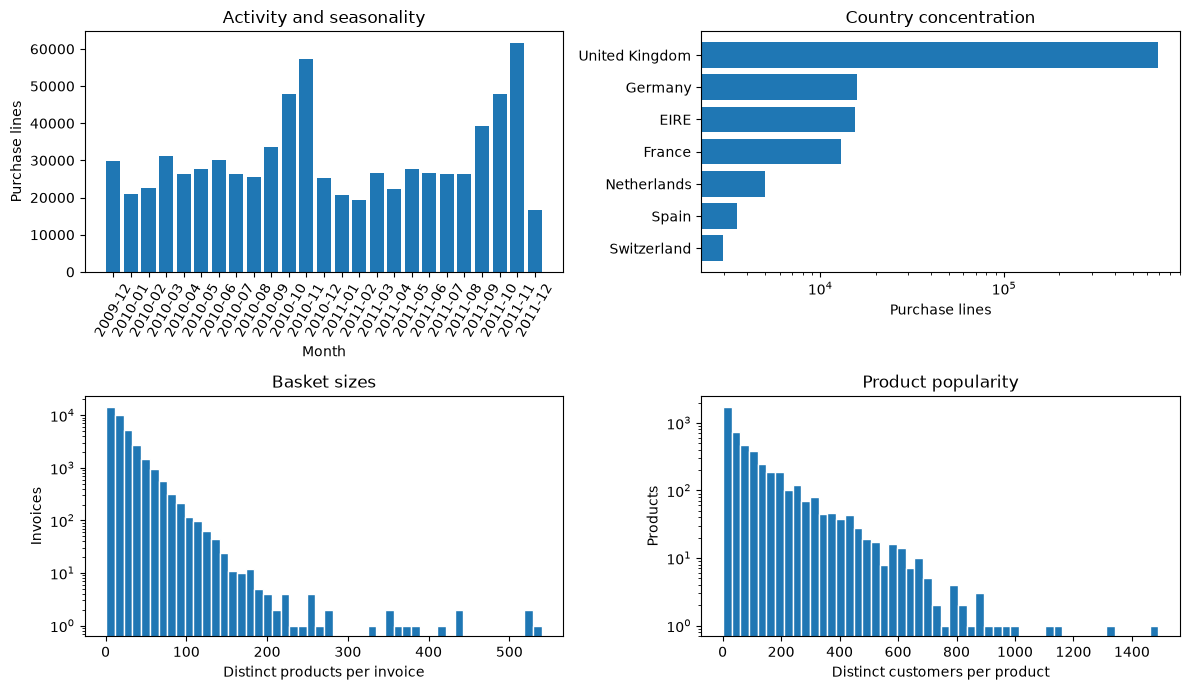

In [3]:
retail_pl = pl.DataFrame({name: events[name].to_numpy() for name in events.columns})
display(pl.DataFrame([cleaning_audit["raw_audit"]]))
display(retail_pl.select("invoice_id", "user_id", "item_id", "description",
                         "quantity", "price", "timestamp", "country").head(8))
display(retail_pl.select(
    pl.len().alias("clean_purchase_lines"),
    pl.col("user_id").n_unique().alias("customers"),
    pl.col("item_id").n_unique().alias("products"),
    pl.col("invoice_id").n_unique().alias("invoices"),
    pl.col("quantity").median().alias("median_units_per_line"),
    pl.col("quantity").quantile(0.99).alias("p99_units_per_line"),
    pl.col("price").median().alias("median_unit_price_GBP"),
    pl.col("price").quantile(0.99).alias("p99_unit_price_GBP"),
))

monthly = retail_pl.group_by(pl.col("timestamp").dt.truncate("1mo").alias("month")).len().sort("month")
countries = retail_pl.group_by("country").agg(
    pl.len().alias("purchase_lines"), pl.col("user_id").n_unique().alias("customers")
).sort("purchase_lines", descending=True)
baskets = retail_pl.group_by("user_id", "invoice_id").agg(
    pl.col("item_id").n_unique().alias("products"), pl.col("quantity").sum().alias("units")
)
product_activity = retail_pl.group_by("item_id").agg(
    pl.col("user_id").n_unique().alias("customers"), pl.len().alias("purchase_lines")
)
customer_activity = retail_pl.group_by("user_id").agg(
    pl.col("invoice_id").n_unique().alias("invoices"), pl.col("item_id").n_unique().alias("products")
)
pair_activity = retail_pl.group_by("user_id", "item_id").len()
repeat_summary = pair_activity.select(
    (pl.col("len") > 1).mean().alias("fraction_of_pairs_with_repeat_purchase"),
    ((pl.col("len") - 1).sum() / pl.col("len").sum()).alias("repeat_line_fraction"),
)
display(countries.head(10))
display(customer_activity.select("invoices", "products").describe())
display(repeat_summary)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
axes[0, 0].bar([str(value)[:7] for value in monthly["month"].to_list()], monthly["len"].to_numpy())
axes[0, 0].set(xlabel="Month", ylabel="Purchase lines", title="Activity and seasonality")
axes[0, 0].tick_params(axis="x", rotation=60)
country_top = countries.head(7)
axes[0, 1].barh(country_top["country"].to_list()[::-1], country_top["purchase_lines"].to_numpy()[::-1])
axes[0, 1].set(xlabel="Purchase lines", title="Country concentration", xscale="log")
axes[1, 0].hist(baskets["products"].to_numpy(), bins=50, edgecolor="white")
axes[1, 0].set(xlabel="Distinct products per invoice", ylabel="Invoices", title="Basket sizes", yscale="log")
axes[1, 1].hist(product_activity["customers"].to_numpy(), bins=50, edgecolor="white")
axes[1, 1].set(xlabel="Distinct customers per product", ylabel="Products", title="Product popularity", yscale="log")
plt.tight_layout()
plt.show()


## 2. Global time cutoffs, full training catalog and repeat purchases

Use a common deployment-style calendar for **all** customers:

| Period | Purchase timestamps |
|---|---|
| Training history | 2009-12-01 through 2011-08-31 |
| Validation | 2011-09-01 through 2011-09-30 |
| Test | 2011-10-01 through 2011-11-30 |

Use all cleaned purchase history preceding validation; the partial month of December 2011 is not evaluated. Whole invoices remain together. Fit all transformations and define the customer/product universe using training history only. The default `MAX_ITEMS=None` and activity thresholds of one retain every observed training product and customer. This includes rare products and short customer histories. Cleaning exclusions still apply, and cold products/customers that first appear in validation or test remain outside this warm-start experiment.

For an optional faster run, cap `MAX_ITEMS` or raise the activity thresholds. A cap selects products by distinct training customer count, never by validation/test popularity. These switches change the evaluation population and relevance sets, so metrics from capped and full-catalog runs are not directly comparable as a quality improvement. The report below shows retained lines and dense-matrix memory before fitting.

The primary task is **product discovery**: recommend products the customer has not purchased in the modeled history. Repeated held-out products are excluded from relevance, just as purchased products are excluded from recommendations. This matters in retail, where repeat buying is common; discovery metrics do not measure replenishment quality. Cold customers/products and repeats are counted explicitly.

Choose settings on September validation only. Refit on train + validation and evaluate October–November once. Product/customer feature vocabularies remain frozen at the original training cutoff. Multiple relevant products per customer support Recall@10 and NDCG@10; each customer receives equal weight.


In [4]:
HISTORY_START = pd.Timestamp("2009-12-01")
TRAIN_END = pd.Timestamp("2011-09-01")
VALID_END = pd.Timestamp("2011-10-01")
TEST_END = pd.Timestamp("2011-12-01")
train_raw = events[(events.timestamp >= HISTORY_START) & (events.timestamp < TRAIN_END)].copy()
valid_raw = events[(events.timestamp >= TRAIN_END) & (events.timestamp < VALID_END)].copy()
test_raw = events[(events.timestamp >= VALID_END) & (events.timestamp < TEST_END)].copy()
assert train_raw.timestamp.max() < valid_raw.timestamp.min()
assert valid_raw.timestamp.max() < test_raw.timestamp.min()
assert set(train_raw.invoice_id).isdisjoint(valid_raw.invoice_id)
assert set(train_raw.invoice_id).isdisjoint(test_raw.invoice_id)
assert set(valid_raw.invoice_id).isdisjoint(test_raw.invoice_id)

product_counts = train_raw.groupby("item_id").user_id.nunique().rename("customers").reset_index()
product_counts = product_counts[product_counts.customers >= MIN_PRODUCT_CUSTOMERS]
product_counts = product_counts.sort_values(["customers", "item_id"], ascending=[False, True])
if MAX_ITEMS is not None:
    product_counts = product_counts.head(MAX_ITEMS)
retained_products = set(product_counts.item_id)
retained_train = train_raw[train_raw.item_id.isin(retained_products)]
customer_counts = retained_train.groupby("user_id").item_id.nunique()
retained_users = customer_counts[customer_counts >= MIN_HISTORY_PRODUCTS].index
retained_train = retained_train[retained_train.user_id.isin(retained_users)].copy()
users = retained_train.groupby("user_id").country.agg(lambda s: s.mode().iloc[0]).reset_index()
products = retained_train.groupby("item_id").agg(
    title=("description", "last"), median_price=("price", "median")
).reset_index()
users = users.sort_values("user_id").reset_index(drop=True)
products = products.sort_values("item_id").reset_index(drop=True)
user_ids, item_ids = users.user_id.to_numpy(), products.item_id.to_numpy()
user_to_idx = {int(value): index for index, value in enumerate(user_ids)}
item_to_idx = {str(value): index for index, value in enumerate(item_ids)}
n_users, n_items = len(users), len(products)

def map_events(frame):
    frame = frame.copy()
    frame["user_idx"] = frame.user_id.map(user_to_idx)
    frame["item_idx"] = frame.item_id.map(item_to_idx)
    return frame

train = map_events(retained_train)
train[["user_idx", "item_idx"]] = train[["user_idx", "item_idx"]].astype(np.int64)
valid, test = map_events(valid_raw), map_events(test_raw)
split_report = pd.DataFrame([
    {"split": name, "raw_purchase_lines": len(raw), "mapped_lines": int(mapped.user_idx.notna().mul(mapped.item_idx.notna()).sum()),
     "raw_customers": raw.user_id.nunique(), "raw_products": raw.item_id.nunique()}
    for name, raw, mapped in [("train", train_raw, train), ("validation", valid_raw, valid), ("test", test_raw, test)]
])
display(split_report)
print(f"Training-selected catalog: {n_users:,} customers, {n_items:,} products")
print("Retained training-line share:", round(len(train) / len(train_raw), 3))

def interaction_matrix(frame, positive_only=True):
    # Every cleaned purchase is positive; repeated pairs become a binary one.
    matrix = sparse.csr_matrix(
        (np.ones(len(frame)), (frame.user_idx.to_numpy(dtype=int), frame.item_idx.to_numpy(dtype=int))),
        shape=(n_users, n_items), dtype=np.float64
    )
    matrix.sum_duplicates()
    matrix.data[:] = 1.0
    return matrix

X_train = interaction_matrix(train)
print("Binary training matrix:", X_train.shape, "distinct pairs:", X_train.nnz)
one_dense_mib = n_items ** 2 * np.dtype(np.float64).itemsize / 2 ** 20
print(f"One dense float64 item matrix: {one_dense_mib:.1f} MiB")
print(f"EASE solve working matrices: roughly {5 * one_dense_mib:.1f} MiB, "
      "plus histories, scores, cached data and other models; not measured peak RAM")


,split,raw_purchase_lines,mapped_lines,raw_customers,raw_products
0,train,600833,600833,5224,4403
1,validation,39166,32112,1259,2539
2,test,109477,80115,2405,2885


Training-selected catalog: 5,224 customers, 4,403 products
Retained training-line share: 1.0
Binary training matrix: (5224, 4403) distinct pairs: 387122
One dense float64 item matrix: 147.9 MiB
EASE solve working matrices: roughly 739.5 MiB, plus histories, scores, cached data and other models; not measured peak RAM


## 3. A shared discovery protocol and popularity baseline

Candidates are training-selected products with a purchase in the current history. Filter every product that the customer purchased in that history. Relevant products are distinct future purchases that are warm, mapped and **previously unpurchased**. Only customers with at least one such product are evaluated. All methods receive exactly the same candidates, customers and relevance sets at a given stage.

For relevant products $H_u$ and ordered recommendations $L_u$:

$$\operatorname{Recall@K}_u=\frac{|L_u\cap H_u|}{|H_u|},\qquad
\operatorname{Precision@K}_u=\frac{|L_u\cap H_u|}{K},$$

$$\operatorname{NDCG@K}_u=
\frac{\sum_{r=1}^K\mathbf 1[L_{u,r}\in H_u]/\log_2(r+1)}
{\sum_{r=1}^{\min(K,|H_u|)}1/\log_2(r+1)}.$$

HitRate records **any** hit; Recall counts how many relevant products were retrieved. Catalog coverage is the fraction of eligible products recommended to at least one customer. Popularity ranks by the number of distinct purchasing customers in history. These are implicit recommendation scores, not prices, quantities or star ratings.


In [5]:
def user_metrics(top, relevant, k):
    hit_mask = np.isin(top, list(relevant)).astype(float)
    discounts = 1 / np.log2(np.arange(2, k + 2))
    hits = float(hit_mask.sum())
    ideal = discounts[:min(k, len(relevant))].sum()
    return {f"Recall@{k}": hits / len(relevant), f"Precision@{k}": hits / k,
            f"NDCG@{k}": float(hit_mask @ discounts[:len(top)] / ideal),
            f"HR@{k}": float(hits > 0)}

def top_items(scores, seen, candidate_mask, k=K):
    eligible = candidate_mask.copy()
    eligible[seen] = False
    candidates = np.flatnonzero(eligible)
    # Equal scores use the same deterministic item-ID order for all methods.
    order = np.lexsort((candidates, -scores[candidates]))
    return candidates[order[:k]]

def evaluate(model, history, heldout, k=K, progress=True):
    positives = interaction_matrix(history)
    all_seen = interaction_matrix(history, positive_only=False)
    item_counts = np.asarray(positives.sum(axis=0)).ravel()
    candidates = item_counts > 0
    warm_users = np.diff(positives.indptr) > 0
    relevant = heldout.drop_duplicates(["user_id", "item_id"])
    mapped = relevant.dropna(subset=["user_idx", "item_idx"]).copy()
    mapped[["user_idx", "item_idx"]] = mapped[["user_idx", "item_idx"]].astype(np.int64)
    warm = mapped[candidates[mapped.item_idx.to_numpy()]
                  & warm_users[mapped.user_idx.to_numpy()]].copy()
    seen_mask = all_seen.toarray().astype(bool)
    repeated = seen_mask[warm.user_idx.to_numpy(), warm.item_idx.to_numpy()]
    eligible = warm[~repeated]
    with threadpool_limits(limits=1):
        scores = np.asarray(model.score_matrix())
    assert scores.shape == (n_users, n_items) and np.isfinite(scores).all()
    rows, recommended = [], set()
    groups = eligible.groupby("user_idx", sort=True)
    for u, group in tqdm(groups, total=groups.ngroups,
                         desc=f"Evaluate {type(model).__name__}", unit="customer",
                         leave=False, mininterval=0.5, disable=not progress):
        seen = all_seen.indices[all_seen.indptr[u]:all_seen.indptr[u + 1]]
        truth = set(group.item_idx)
        assert truth.isdisjoint(seen)
        top = top_items(scores[u], seen, candidates, k)
        recommended.update(top.tolist())
        rows.append({"user_idx": int(u), "history_length": len(seen),
                     "relevant_items": len(truth), **user_metrics(top, truth, k)})
    details = pd.DataFrame(rows)
    metrics = {name: float(details[name].mean()) for name in
               [f"Recall@{k}", f"Precision@{k}", f"NDCG@{k}", f"HR@{k}"]}
    metrics.update(eval_users=len(details), heldout_positives=len(relevant),
                   unmapped_pairs=len(relevant) - len(mapped), repeated_pairs=int(repeated.sum()),
                   eligible_positives=len(eligible), candidate_items=int(candidates.sum()),
                   coverage=len(recommended) / candidates.sum())
    return metrics, details

class Popularity:
    def fit(self, matrix):
        self.counts = np.asarray(matrix.sum(axis=0)).ravel()
        self.n_users = matrix.shape[0]
        return self

    def score_matrix(self):
        return np.broadcast_to(self.counts, (self.n_users, len(self.counts)))

def timed_fit(model, *args, **kwargs):
    started = perf_counter()
    with threadpool_limits(limits=1):
        model.fit(*args, **kwargs)
    model.fit_seconds_ = perf_counter() - started
    return model

metric_check = user_metrics(np.array([1, 9, 2]), {1, 2}, k=3)
assert metric_check["Recall@3"] == 1.0 and metric_check["Precision@3"] == 2 / 3
assert np.isclose(metric_check["NDCG@3"], (1 + 0.5) / (1 + 1 / np.log2(3)))
popularity_valid = timed_fit(Popularity(), X_train)
baseline_validation, _ = evaluate(popularity_valid, train, valid)
display(pd.Series(baseline_validation, name="Popularity validation").to_frame().round(4))


,Popularity validation
Recall@10,0.0192
Precision@10,0.0287
NDCG@10,0.0310
HR@10,0.2274
eval_users,972.0000
heldout_positives,37087.0000
unmapped_pairs,6882.0000
repeated_pairs,14093.0000
eligible_positives,16112.0000
candidate_items,4403.0000


## 4. SLIM: sparse nonnegative item-to-item reconstruction

For a binary positive-event matrix $X\in\mathbb R^{m\times n}$, learn $B$ by

$$\min_{B\geq0,\;\operatorname{diag}(B)=0}
\frac12\|X-XB\|_F^2+\lambda_1\|B\|_1+\frac{\lambda_2}{2}\|B\|_F^2.$$

Column $j$ predicts product $j$ from all other products. The zero diagonal prevents copying the target column; nonnegativity permits only positive associations. Unobserved purchases participate as zeros in **reconstruction**; these are not verified negative preferences.

The column problems are elastic-net regressions. For $G=X^\top X$, a nonnegative coordinate update is

$$b_{ij}\leftarrow\frac{\max(0,G_{ij}-\sum_{k\ne i}G_{ik}b_{kj}-\lambda_1)}{G_{ii}+\lambda_2},\quad i\ne j.$$

scikit-learn minimizes $\|y-Xw\|^2/(2m)+\text{alpha}\,\text{l1_ratio}\|w\|_1+\text{alpha}(1-\text{l1_ratio})\|w\|^2/2$. To solve the objective above, use

$$\text{alpha}=(\lambda_1+\lambda_2)/m,\qquad
\text{l1_ratio}=\lambda_1/(\lambda_1+\lambda_2).$$

We temporarily zero column $j$ while fitting its regression and restore it immediately afterward. The learned matrix is stored sparsely. Scores are $S=XB$, with **row = source product, column = candidate product**. Reference: [Ning and Karypis (2011)](https://doi.org/10.1109/ICDM.2011.134).


In [6]:
class SLIM:
    def __init__(self, l1=5.0, l2=5.0, max_iter=1000, tol=1e-4, progress=True):
        self.l1, self.l2 = l1, l2
        self.max_iter, self.tol = max_iter, tol
        self.progress = progress

    def fit(self, matrix):
        self.history = sparse.csr_matrix(matrix, dtype=np.float64).copy()
        design = self.history.tocsc(copy=True)
        m, n = design.shape
        solver = ElasticNet(alpha=(self.l1 + self.l2) / m,
                            l1_ratio=self.l1 / (self.l1 + self.l2),
                            fit_intercept=False, positive=True, copy_X=False,
                            max_iter=self.max_iter, tol=self.tol, selection="cyclic")
        rows, columns, values = [], [], []
        self.convergence_warnings_ = 0
        self.iterations_ = []
        for j in tqdm(range(n), desc="SLIM product regressions", unit="product",
                      leave=False, mininterval=0.5, disable=not self.progress):
            target = design[:, j].toarray().ravel()
            if not np.any(target):
                continue
            start, end = design.indptr[j:j + 2]
            saved = design.data[start:end].copy()
            design.data[start:end] = 0
            try:
                with warnings.catch_warnings(record=True) as messages:
                    warnings.simplefilter("always", ConvergenceWarning)
                    solver.fit(design, target)
                for warning in messages:
                    if issubclass(warning.category, ConvergenceWarning):
                        self.convergence_warnings_ += 1
                    else:
                        warnings.warn(warning.message, warning.category)
            finally:
                design.data[start:end] = saved
            weights = solver.coef_.copy()
            weights[j] = 0
            selected = np.flatnonzero(weights)
            rows.extend(selected.tolist())
            columns.extend([j] * len(selected))
            values.extend(weights[selected].tolist())
            self.iterations_.append(solver.n_iter_)
        self.W = sparse.csc_matrix((values, (rows, columns)), shape=(n, n))
        assert not np.any(self.W.diagonal()) and np.all(self.W.data >= 0)
        return self

    def score_matrix(self):
        return (self.history @ self.W).toarray()


## 5. EASE: a dense closed-form solution

Remove the L1 penalty and the sign constraint, while retaining the zero diagonal:

$$\min_{\operatorname{diag}(B)=0}\|X-XB\|_F^2+\lambda\|B\|_F^2.$$

For column $j$, the stationarity condition is $(G+\lambda I)b_j=G_{:j}-\eta_j e_j$. Enforcing $b_{jj}=0$ gives

$$P=(G+\lambda I)^{-1},\qquad
B_{ij}=-\frac{P_{ij}}{P_{jj}}\ (i\ne j),\qquad B_{jj}=0.$$

The division is **column-wise**. EASE can learn negative and asymmetric relationships; clipping negative weights changes its solution. We obtain $P$ through a Cholesky solve against the identity rather than calling `np.linalg.inv`, but still materialize a dense inverse-sized matrix. Memory is $O(n^2)$ and factorization time is $O(n^3)$: a small notebook catalog is not evidence that EASE scales to millions of products. Reference: [Steck (2019)](https://arxiv.org/abs/1905.03375).


In [7]:
class EASE:
    def __init__(self, reg=100.0, progress=True):
        self.reg = reg
        self.progress = progress

    def fit(self, matrix):
        if self.reg <= 0:
            raise ValueError("EASE regularization must be positive")
        self.history = sparse.csr_matrix(matrix, dtype=np.float64).copy()
        with tqdm(total=3, desc="EASE stages", unit="stage", leave=False,
                  mininterval=0.5, disable=not self.progress) as progress:
            progress.set_postfix_str("Gram matrix")
            gram = (self.history.T @ self.history).toarray()
            gram.flat[::gram.shape[0] + 1] += self.reg
            progress.update(1)
            progress.set_postfix_str("Cholesky solve")
            factor = linalg.cho_factor(gram, lower=True, check_finite=False)
            precision = linalg.cho_solve(factor, np.eye(gram.shape[0]), check_finite=False)
            progress.update(1)
            progress.set_postfix_str("Weight normalization")
            self.W = -precision / np.diag(precision)[None, :]
            np.fill_diagonal(self.W, 0)
            assert np.isfinite(self.W).all()
            progress.update(1)
        return self

    def score_matrix(self):
        return self.history @ self.W

# KKT checks test the solved objectives, including the diagonal constraint
# and the scaling between SLIM's objective and ElasticNet's objective.
rng_check = np.random.default_rng(7)
toy = sparse.csr_matrix((rng_check.random((50, 8)) < 0.3).astype(float))
toy_gram = (toy.T @ toy).toarray()
slim_toy = timed_fit(SLIM(l1=0.3, l2=2.0, tol=1e-10, max_iter=10000, progress=False), toy)
W_toy = slim_toy.W.toarray()
gradient = toy_gram @ W_toy - toy_gram + 2.0 * W_toy + 0.3
off_diagonal = ~np.eye(8, dtype=bool)
active = off_diagonal & (W_toy > 1e-7)
assert np.max(np.abs(gradient[active])) < 1e-5
assert np.min(gradient[off_diagonal & ~active]) > -1e-5
assert (slim_toy.history != toy).nnz == 0
ease_toy = timed_fit(EASE(reg=2.0, progress=False), toy)
stationarity = (toy_gram + 2.0 * np.eye(8)) @ ease_toy.W - toy_gram
assert np.max(np.abs(stationarity[off_diagonal])) < 1e-10
assert not np.any(ease_toy.W.diagonal())
print("SLIM and EASE objective/constraint checks passed")


SLIM and EASE objective/constraint checks passed


### Select reconstruction settings on validation

The grid is deliberately small. SLIM's L1 controls sparsity; L2 stabilizes correlated predictors. EASE's L2 controls shrinkage. All users are included in tuning. Choose by validation NDCG@10 and report solver convergence; the test split plays no role.


In [8]:
SLIM_GRID = [{"l1": 1.0, "l2": 5.0}, {"l1": 5.0, "l2": 5.0},
             {"l1": 5.0, "l2": 20.0}]
EASE_GRID = [{"reg": 10.0}, {"reg": 100.0}, {"reg": 500.0}]
search_rows, selected_settings = [], {}
for name, model_class, grid in [("SLIM", SLIM, SLIM_GRID), ("EASE", EASE, EASE_GRID)]:
    model_rows = []
    for setting in tqdm(grid, desc=f"{name} validation grid", unit="config"):
        model = timed_fit(model_class(**setting), X_train)
        metrics, _ = evaluate(model, train, valid)
        row = {"model": name, "setting": str(setting), "fit_seconds": model.fit_seconds_,
               "solver_warnings": getattr(model, "convergence_warnings_", 0), **metrics}
        search_rows.append(row)
        model_rows.append(row)
    best_index = int(np.argmax([row[f"NDCG@{K}"] for row in model_rows]))
    selected_settings[name] = grid[best_index]
linear_search = pd.DataFrame(search_rows)
display(linear_search[["model", "setting", f"Recall@{K}", f"NDCG@{K}",
                       "fit_seconds", "solver_warnings"]].round(4))
print("Selected on validation:", selected_settings)
assert linear_search.solver_warnings.sum() == 0, "Increase SLIM max_iter before accepting this run"


,model,setting,Recall@10,NDCG@10,fit_seconds,solver_warnings
0,SLIM,"{'l1': 1.0, 'l2': 5.0}",0.0499,0.0692,32.0946,0
1,SLIM,"{'l1': 5.0, 'l2': 5.0}",0.0520,0.0713,27.0391,0
2,SLIM,"{'l1': 5.0, 'l2': 20.0}",0.0530,0.0721,27.4273,0
3,EASE,{'reg': 10.0},0.0432,0.0606,4.2452,0
4,EASE,{'reg': 100.0},0.0504,0.0745,4.1890,0
5,EASE,{'reg': 500.0},0.0549,0.0780,4.2208,0


Selected on validation: {'SLIM': {'l1': 5.0, 'l2': 20.0}, 'EASE': {'reg': 500.0}}


## 6. Factorization Machines: arbitrary sparse feature interactions

An order-two FM uses a feature vector $x\in\mathbb R^d$:

$$s(x)=w_0+\sum_a w_a x_a+\sum_{a<b}\langle v_a,v_b\rangle x_ax_b.$$

With user/product one-hot IDs only, this is $w_0+b_u+b_i+\langle p_u,q_i\rangle$: biased matrix factorization. Add **customer country**, **TF-IDF product-description tokens** and **product price buckets** to share interactions between attributes. All descriptions, median prices, country profiles, vocabularies and bucket boundaries come from training history. The future transaction's price, quantity or basket composition is not a feature.

FM includes within-side and cross-side feature interactions; it is not identical to LightFM's feature-embedding model. The identity

$$\sum_{a<b}\langle v_a,v_b\rangle x_ax_b=
\frac12\sum_f\left[\left(\sum_a v_{af}x_a\right)^2-\sum_a v_{af}^2x_a^2\right]$$

reduces computation to $O(k\,\mathrm{nnz}(x))$, with gradient

$$\frac{\partial s(x)}{\partial v_{af}}=
x_a\left(\sum_b v_{bf}x_b-v_{af}x_a\right).$$

Reference: [Rendle (2010)](https://doi.org/10.1109/ICDM.2010.127).


In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer

def normalize_rows(matrix):
    matrix = sparse.csr_matrix(matrix, dtype=np.float64)
    norms = np.sqrt(np.asarray(matrix.multiply(matrix).sum(axis=1)).ravel())
    return sparse.diags(np.divide(1, norms, out=np.zeros_like(norms), where=norms > 0)) @ matrix

user_side = normalize_rows(sparse.csr_matrix(pd.get_dummies(users.country, dtype=float).to_numpy()))
text_encoder = TfidfVectorizer(lowercase=True, max_features=256, min_df=2, norm="l2")
description_features = text_encoder.fit_transform(products.title)
price_boundaries = np.unique(np.quantile(products.median_price, [0.25, 0.5, 0.75]))
price_bucket = np.searchsorted(price_boundaries, products.median_price, side="right")
price_features = sparse.csr_matrix(
    (np.ones(n_items), (np.arange(n_items), price_bucket)),
    shape=(n_items, len(price_boundaries) + 1)
)
item_side = normalize_rows(sparse.hstack([description_features, price_features], format="csr"))

class FeatureMap:
    def __init__(self, use_side_features):
        self.label = "IDs + metadata" if use_side_features else "IDs"
        self.user_features = sparse.eye(n_users, format="csr")
        self.item_features = sparse.eye(n_items, format="csr")
        if use_side_features:
            self.user_features = sparse.hstack([self.user_features, user_side], format="csr")
            self.item_features = sparse.hstack([self.item_features, item_side], format="csr")
        self.user_dim = self.user_features.shape[1]
        self.n_features = self.user_dim + self.item_features.shape[1]

    def pairs(self, user_indices, item_indices):
        return sparse.hstack([self.user_features[user_indices], self.item_features[item_indices]], format="csr")

features_ids = FeatureMap(use_side_features=False)
features_side = FeatureMap(use_side_features=True)
print("ID-only features:", features_ids.n_features)
print("ID + metadata features:", features_side.n_features)
print("Training median-price bucket boundaries:", price_boundaries)
print("Side blocks are L2-normalized per row; identity features retain weight one")


ID-only features: 9627
ID + metadata features: 9928
Training median-price bucket boundaries: [1.25 2.1  4.15]
Side blocks are L2-normalized per row; identity features retain weight one


### BPR training and negative sampling

For a purchased product $i$ and an unobserved candidate $j$ for the same customer, minimize

$$L=\frac1{|D|}\sum_{(u,i,j)\in D}\log(1+\exp[-(s(u,i)-s(u,j))])
+\frac{\lambda}{2}(\|w\|^2+\|V\|_F^2).$$

For $\Delta=s(u,i)-s(u,j)$, $\partial\ell/\partial s^+=-\sigma(-\Delta)$ and $\partial\ell/\partial s^-=\sigma(-\Delta)$. Combine both gradients **before** updating parameters; use Adam for minibatch optimization. The global bias cancels and is fixed at zero.

By default, each epoch shuffles and visits **every distinct training customer–product pair once** (`FM_SAMPLES_PER_EPOCH=None`). Both FM ablations use the same full-pass rule. An optional numeric budget instead draws at most that many positive pairs uniformly with replacement; that faster mode approximates the uniform positive-pair objective and is not a complete epoch.

Negatives are uniform training-warm products, rejecting everything the customer purchased in training history. Validation/test purchases are never consulted. Future positives can therefore be sampled as unlabeled negatives. Customers who bought every candidate cannot supply a negative and are omitted from FM training. BPR and WARP are different objectives/sampling mechanisms.

Compare **IDs only** with **IDs + training-derived metadata** using the same loss, optimizer, seed and validation checkpoint grid. Metadata is not guaranteed to improve quality. Feature transforms remain frozen at the training cutoff during final refitting.


In [10]:
def sample_negatives(rng, user_indices, seen_mask, candidate_ids):
    if np.any(seen_mask[user_indices][:, candidate_ids].all(axis=1)):
        raise ValueError("A sampled user has seen every candidate")
    negative = rng.choice(candidate_ids, size=len(user_indices))
    collisions = seen_mask[user_indices, negative]
    while np.any(collisions):
        negative[collisions] = rng.choice(candidate_ids, size=int(collisions.sum()))
        collisions = seen_mask[user_indices, negative]
    return negative

class FactorizationMachine:
    def __init__(self, n_factors=16, epochs=30, lr=0.01, reg=1e-5,
                 batch_size=512, random_state=42, progress=True):
        self.n_factors, self.epochs, self.lr = n_factors, epochs, lr
        self.reg, self.batch_size, self.random_state = reg, batch_size, random_state
        self.progress = progress

    def initialize(self, features):
        self.features = features
        rng = np.random.default_rng(self.random_state)
        self.w = np.zeros(features.n_features)
        self.V = 0.05 * rng.standard_normal((features.n_features, self.n_factors))
        self.m_w, self.s_w = np.zeros_like(self.w), np.zeros_like(self.w)
        self.m_v, self.s_v = np.zeros_like(self.V), np.zeros_like(self.V)
        self.step = 0

    def forward(self, X):
        squared = X.multiply(X)
        projected = X @ self.V
        scores = np.asarray(X @ self.w).ravel() + 0.5 * np.sum(
            projected ** 2 - squared @ (self.V ** 2), axis=1
        )
        return scores, projected, squared

    def gradients(self, X, projected, squared, errors):
        grad_w = np.asarray(X.T @ errors).ravel()
        grad_v = (X.T @ (errors[:, None] * projected)
                  - np.asarray(squared.T @ errors).ravel()[:, None] * self.V)
        return grad_w, np.asarray(grad_v)

    def bpr_gradients(self, X_pos, X_neg):
        pos, projected_pos, squared_pos = self.forward(X_pos)
        neg, projected_neg, squared_neg = self.forward(X_neg)
        delta = pos - neg
        weight = expit(-delta)
        gw_pos, gv_pos = self.gradients(X_pos, projected_pos, squared_pos, -weight)
        gw_neg, gv_neg = self.gradients(X_neg, projected_neg, squared_neg, weight)
        size = X_pos.shape[0]
        loss = float(np.logaddexp(0, -delta).mean())
        loss += 0.5 * self.reg * (np.sum(self.w ** 2) + np.sum(self.V ** 2))
        return loss, (gw_pos + gw_neg) / size + self.reg * self.w, \
            (gv_pos + gv_neg) / size + self.reg * self.V

    def update(self, grad_w, grad_v):
        self.step += 1
        for parameter, first, second, gradient in [
            (self.w, self.m_w, self.s_w, grad_w),
            (self.V, self.m_v, self.s_v, grad_v),
        ]:
            first *= 0.9
            first += 0.1 * gradient
            second *= 0.999
            second += 0.001 * gradient ** 2
            parameter -= self.lr * (first / (1 - 0.9 ** self.step)) / (
                np.sqrt(second / (1 - 0.999 ** self.step)) + 1e-8
            )

    def score_matrix(self):
        # Split x into disjoint user/item blocks. Their cross interaction
        # factors, while within-block FM terms become user/item offsets.
        boundary = self.features.user_dim
        U, I = self.features.user_features, self.features.item_features
        Vu, Vi = self.V[:boundary], self.V[boundary:]
        projected_u, projected_i = U @ Vu, I @ Vi
        offset_u = U @ self.w[:boundary] + 0.5 * np.sum(
            projected_u ** 2 - U.multiply(U) @ (Vu ** 2), axis=1
        )
        offset_i = I @ self.w[boundary:] + 0.5 * np.sum(
            projected_i ** 2 - I.multiply(I) @ (Vi ** 2), axis=1
        )
        return offset_u[:, None] + offset_i[None, :] + projected_u @ projected_i.T

    def fit(self, history, features, validation=None, checkpoints=None):
        self.initialize(features)
        positives = history.drop_duplicates(["user_idx", "item_idx"])
        positive_matrix = interaction_matrix(history)
        seen = interaction_matrix(history, positive_only=False).toarray().astype(bool)
        candidates = np.flatnonzero(np.asarray(positive_matrix.sum(axis=0)).ravel() > 0)
        saturated = seen[:, candidates].all(axis=1)
        positives = positives[~saturated[positives.user_idx.to_numpy()]]
        positive_users = positives.user_idx.to_numpy()
        positive_items = positives.item_idx.to_numpy()
        rng = np.random.default_rng(self.random_state)
        self.history_, self.best_epoch_ = [], self.epochs
        best_metric, best_parameters = -np.inf, None
        checkpoints = checkpoints or [self.epochs]
        label = f"FM-BPR {features.label}"
        with tqdm(total=self.epochs, desc=label + " epochs", unit="epoch",
                  mininterval=0.5, disable=not self.progress) as epoch_progress, \
             tqdm(total=0, desc="Minibatches", unit="batch", leave=False,
                  mininterval=0.5, disable=not self.progress) as batch_progress:
            for epoch in range(1, self.epochs + 1):
                if FM_SAMPLES_PER_EPOCH is None:
                    order = rng.permutation(len(positives))
                else:
                    sample_count = min(len(positives), FM_SAMPLES_PER_EPOCH)
                    order = rng.integers(0, len(positives), size=sample_count)
                total_loss = 0.0
                batch_progress.reset(total=(len(order) + self.batch_size - 1) // self.batch_size)
                batch_progress.set_description(f"{label}, epoch {epoch}")
                for start in range(0, len(order), self.batch_size):
                    batch = order[start:start + self.batch_size]
                    u, i = positive_users[batch], positive_items[batch]
                    j = sample_negatives(rng, u, seen, candidates)
                    assert not seen[u, j].any()
                    X_pos, X_neg = features.pairs(u, i), features.pairs(u, j)
                    loss, grad_w, grad_v = self.bpr_gradients(X_pos, X_neg)
                    self.update(grad_w, grad_v)
                    total_loss += loss * len(batch)
                    batch_progress.update(1)
                record = {"epoch": epoch, "training_bpr": total_loss / len(order)}
                status = {"loss": f"{record['training_bpr']:.4f}"}
                if validation is not None and epoch in checkpoints:
                    metrics, _ = evaluate(self, history, validation, progress=False)
                    record[f"validation_NDCG@{K}"] = metrics[f"NDCG@{K}"]
                    status["val_NDCG"] = f"{metrics[f'NDCG@{K}']:.4f}"
                    if metrics[f"NDCG@{K}"] > best_metric:
                        best_metric = metrics[f"NDCG@{K}"]
                        self.best_epoch_ = epoch
                        best_parameters = (self.w.copy(), self.V.copy())
                self.history_.append(record)
                epoch_progress.set_postfix(status)
                epoch_progress.update(1)
        if best_parameters is not None:
            self.w, self.V = best_parameters
        assert np.isfinite(self.V).all() and np.isfinite(self.w).all()
        return self


### Verify the FM formula, gradient and scorer

Before fitting real data, compare the efficient interaction formula with explicit feature-pair enumeration, check BPR gradients by finite differences, verify that ID-only FM recovers biased matrix factorization, and compare the fast all-item scorer with the generic feature scorer. These checks catch subtle gradient, orientation and feature-index mistakes.


In [11]:
fm_check = FactorizationMachine(n_factors=3, reg=0.02)
fm_check.initialize(features_side)
pair_users, pair_items = np.array([0, 2]), np.array([1, 4])
X_check = features_side.pairs(pair_users, pair_items)
fast, _, _ = fm_check.forward(X_check)
brute = []
for row in X_check:
    active, values = row.indices, row.data
    score = row @ fm_check.w
    score = float(np.asarray(score).ravel()[0])
    for a in range(len(active)):
        for b in range(a + 1, len(active)):
            score += values[a] * values[b] * (fm_check.V[active[a]] @ fm_check.V[active[b]])
    brute.append(score)
assert np.allclose(fast, brute, atol=1e-12)
assert np.allclose(fast, fm_check.score_matrix()[pair_users, pair_items], atol=1e-12)
X_negative = features_side.pairs(pair_users, np.array([6, 8]))
_, grad_w, grad_v = fm_check.bpr_gradients(X_check, X_negative)
epsilon = 1e-6
coordinates = [(fm_check.w, grad_w, 0),
               (fm_check.w, grad_w, features_side.user_dim + 1),
               (fm_check.V, grad_v, (0, 1)),
               (fm_check.V, grad_v, (features_side.user_dim + 1, 2))]
for parameter, gradient, index in coordinates:
    saved = parameter[index]
    parameter[index] = saved + epsilon
    plus = fm_check.bpr_gradients(X_check, X_negative)[0]
    parameter[index] = saved - epsilon
    minus = fm_check.bpr_gradients(X_check, X_negative)[0]
    parameter[index] = saved
    assert np.isclose((plus - minus) / (2 * epsilon), gradient[index], atol=1e-7)
fm_ids_check = FactorizationMachine(n_factors=3)
fm_ids_check.initialize(features_ids)
score_ids, _, _ = fm_ids_check.forward(features_ids.pairs(pair_users, pair_items))
assert np.allclose(score_ids,
    fm_ids_check.w[pair_users] + fm_ids_check.w[n_users + pair_items]
    + np.sum(fm_ids_check.V[pair_users] * fm_ids_check.V[n_users + pair_items], axis=1))
print("FM equation, BPR gradients, ID equivalence and fast scoring checks passed")


FM equation, BPR gradients, ID equivalence and fast scoring checks passed


Training FM-BPR IDs for validation...


FM-BPR IDs selected epoch: 6 seconds: 45.6
Training FM-BPR + metadata for validation...


FM-BPR + metadata selected epoch: 3 seconds: 49.59


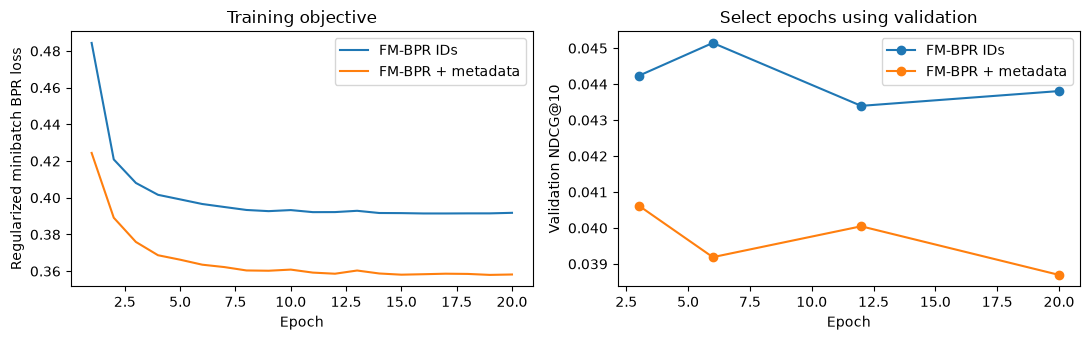

Training loss uses freshly sampled negatives; changes are not a fixed-triplet loss curve


In [12]:
fm_validation, fm_epochs = {}, {}
for name, features in [("FM-BPR IDs", features_ids), ("FM-BPR + metadata", features_side)]:
    print("Training", name, "for validation...", flush=True)
    model = timed_fit(FactorizationMachine(epochs=max(FM_CHECKPOINTS), random_state=SEED),
                      train, features, validation=valid, checkpoints=FM_CHECKPOINTS)
    fm_validation[name] = model
    fm_epochs[name] = model.best_epoch_
    print(name, "selected epoch:", model.best_epoch_, "seconds:", round(model.fit_seconds_, 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, model in fm_validation.items():
    history = pd.DataFrame(model.history_)
    axes[0].plot(history.epoch, history.training_bpr, label=name)
    checkpoints = history.dropna(subset=[f"validation_NDCG@{K}"])
    axes[1].plot(checkpoints.epoch, checkpoints[f"validation_NDCG@{K}"], marker="o", label=name)
axes[0].set(xlabel="Epoch", ylabel="Regularized minibatch BPR loss", title="Training objective")
axes[1].set(xlabel="Epoch", ylabel=f"Validation NDCG@{K}", title="Select epochs using validation")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
print("Training loss uses freshly sampled negatives; changes are not a fixed-triplet loss curve")


## 7. Refit and evaluate the untouched test period

Refit selected SLIM/EASE settings and FM epoch counts on train + mapped September validation purchases. Freeze the original customer/product universe and feature transforms. Update purchasing histories and negative pools from the combined period; exclude those purchases from discovery recommendations and October–November relevance. Test information does not determine parameters, catalog or feature transforms.

SLIM/EASE minimize binary reconstruction error; FM minimizes a pairwise loss. A common **product-discovery target** permits Recall/NDCG comparison despite different training losses. We do not interpret scores as prices or claim that one loss is inherently superior.


In [13]:
mapped_valid = valid.dropna(subset=["user_idx", "item_idx"]).copy()
mapped_valid[["user_idx", "item_idx"]] = mapped_valid[["user_idx", "item_idx"]].astype(np.int64)
final_history = pd.concat([train, mapped_valid], ignore_index=True)
X_final = interaction_matrix(final_history)
final_jobs = [
    ("Popularity", Popularity(), (X_final,)),
    ("SLIM", SLIM(**selected_settings["SLIM"]), (X_final,)),
    ("EASE", EASE(**selected_settings["EASE"]), (X_final,)),
    ("FM-BPR IDs", FactorizationMachine(epochs=fm_epochs["FM-BPR IDs"], random_state=SEED),
     (final_history, features_ids)),
    ("FM-BPR + metadata", FactorizationMachine(epochs=fm_epochs["FM-BPR + metadata"], random_state=SEED),
     (final_history, features_side)),
]
models = {}
with tqdm(total=len(final_jobs), desc="Final refit", unit="model") as progress:
    for name, model, arguments in final_jobs:
        progress.set_postfix_str(name)
        models[name] = timed_fit(model, *arguments)
        progress.update(1)
assert models["SLIM"].convergence_warnings_ == 0

def model_bytes(model):
    if hasattr(model, "W"):
        W = model.W
        return W.data.nbytes + W.indices.nbytes + W.indptr.nbytes if sparse.issparse(W) else W.nbytes
    if hasattr(model, "V"):
        return model.V.nbytes + model.w.nbytes
    return model.counts.nbytes

test_rows, test_details = [], {}
for name, model in tqdm(models.items(), desc="Test evaluation", unit="model"):
    metrics, details = evaluate(model, final_history, test)
    test_rows.append({"model": name, "final_fit_seconds": model.fit_seconds_,
                      "parameter_MiB": model_bytes(model) / 2 ** 20, **metrics})
    test_details[name] = details
comparison = pd.DataFrame(test_rows).set_index("model")
display(comparison[[f"Recall@{K}", f"NDCG@{K}", f"Precision@{K}", f"HR@{K}", "coverage",
                    "final_fit_seconds", "parameter_MiB"]].round(4))
eligibility_columns = ["eval_users", "eligible_positives", "candidate_items"]
assert (comparison[eligibility_columns].nunique() == 1).all()
print("Common test eligibility:", comparison.iloc[0][eligibility_columns + ["heldout_positives", "unmapped_pairs", "repeated_pairs"]].to_dict())
print("Eligible positives per evaluated user:",
      test_details["Popularity"].relevant_items.describe().round(2).to_dict())


,Recall@10,NDCG@10,Precision@10,HR@10,coverage,final_fit_seconds,parameter_MiB
model,,,,,,,
Popularity,0.0194,0.0388,0.0352,0.2572,0.0182,0.0037,0.0336
SLIM,0.0432,0.0723,0.0594,0.3844,0.3968,29.2753,1.5375
EASE,0.0510,0.0821,0.0676,0.4266,0.2537,4.2674,147.9066
FM-BPR IDs,0.0293,0.0551,0.0485,0.3303,0.1381,13.6042,1.2486
FM-BPR + metadata,0.0204,0.0418,0.0378,0.2724,0.1151,7.1373,1.2877


Common test eligibility: {'eval_users': 1777.0, 'eligible_positives': 37836.0, 'candidate_items': 4403.0, 'heldout_positives': 92730.0, 'unmapped_pairs': 26113.0, 'repeated_pairs': 28781.0}
Eligible positives per evaluated user: {'count': 1777.0, 'mean': 21.29, 'std': 25.07, 'min': 1.0, '25%': 6.0, '50%': 14.0, '75%': 28.0, 'max': 492.0}


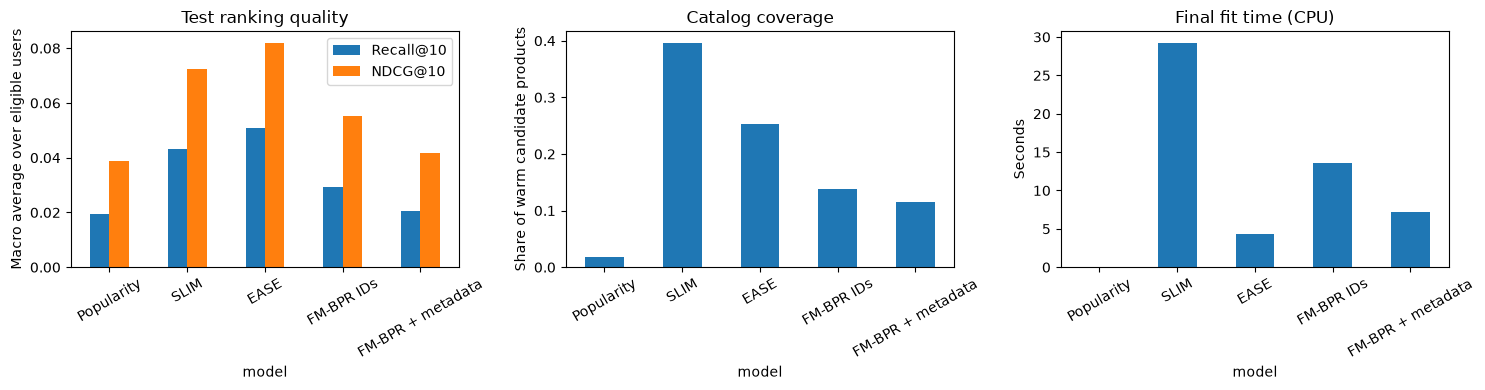

Timing is machine-dependent. parameter_MiB counts learned parameters, not peak process memory


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
comparison[[f"Recall@{K}", f"NDCG@{K}"]].plot.bar(ax=axes[0], title="Test ranking quality")
comparison.coverage.plot.bar(ax=axes[1], title="Catalog coverage")
comparison.final_fit_seconds.plot.bar(ax=axes[2], title="Final fit time (CPU)")
axes[0].set_ylabel("Macro average over eligible users")
axes[1].set_ylabel("Share of warm candidate products")
axes[2].set_ylabel("Seconds")
for ax in axes:
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print("Timing is machine-dependent. parameter_MiB counts learned parameters, not peak process memory")


### Is a small difference reliable?

Use a **paired user bootstrap** for NDCG differences: resample the same users for both methods. This measures variation across users in this split, not variability across training seeds or datasets. The intervals are exploratory and do not correct for multiple comparisons. If an interval includes zero, this experiment does not establish a reliable gain. No settings are chosen from these test diagnostics.


,difference,mean_delta,95% lower,95% upper
0,SLIM minus Popularity,0.0334,0.0273,0.0399
1,EASE minus Popularity,0.0432,0.0365,0.0500
2,FM-BPR + metadata minus FM-BPR IDs,-0.0134,-0.0177,-0.0088


model,EASE,FM-BPR + metadata,FM-BPR IDs,Popularity,SLIM
history_bin,,,,,
≤30,0.0779,0.0373,0.0508,0.0356,0.0653
31–100,0.0891,0.0435,0.0606,0.0438,0.0783
>100,0.0778,0.0422,0.0523,0.0359,0.0701


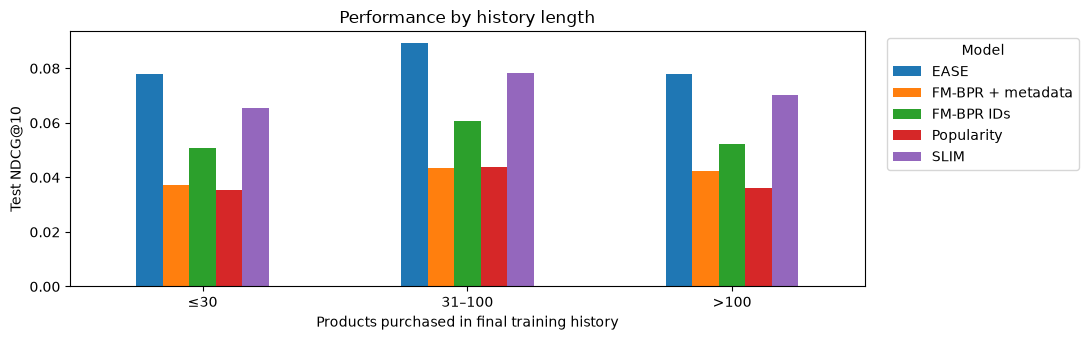

In [15]:
bootstrap_rng = np.random.default_rng(SEED)
interval_rows = []
for first, second in [("SLIM", "Popularity"), ("EASE", "Popularity"),
                      ("FM-BPR + metadata", "FM-BPR IDs")]:
    a = test_details[first].set_index("user_idx")[f"NDCG@{K}"]
    b = test_details[second].set_index("user_idx")[f"NDCG@{K}"]
    assert a.index.equals(b.index)
    delta = (a - b).to_numpy()
    samples = bootstrap_rng.integers(0, len(delta), size=(1000, len(delta)))
    low, high = np.quantile(delta[samples].mean(axis=1), [0.025, 0.975])
    interval_rows.append({"difference": first + " minus " + second,
                          "mean_delta": delta.mean(), "95% lower": low, "95% upper": high})
display(pd.DataFrame(interval_rows).round(4))

group_rows = []
for name, detail in test_details.items():
    detail = detail.copy()
    detail["history_bin"] = pd.cut(detail.history_length, [0, 30, 100, np.inf],
                                    labels=["≤30", "31–100", ">100"])
    for history_bin, group in detail.groupby("history_bin", observed=True):
        group_rows.append({"model": name, "history_bin": history_bin,
                           "users": len(group), f"NDCG@{K}": group[f"NDCG@{K}"].mean()})
group_report = pd.DataFrame(group_rows)
group_quality = group_report.pivot(index="history_bin", columns="model", values=f"NDCG@{K}")
group_quality = group_quality.reindex(["≤30", "31–100", ">100"])
display(group_quality.round(4))
ax = group_quality.plot.bar(figsize=(11, 3.5))
ax.legend(title="Model", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.ylabel(f"Test NDCG@{K}")
plt.xlabel("Products purchased in final training history")
plt.title("Performance by history length")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 8. Inspect learned product relationships

SLIM produces sparse nonnegative coefficients; EASE usually produces a dense matrix containing both signs. Both can be asymmetric. A coefficient tells how much a purchased **source** product contributes to an unseen **candidate** product; recommendations sum contributions over history. Negative EASE weights are conditional reconstruction associations, not evidence of dislike. Heatmaps show a fixed set of frequent products; inspect named examples before interpreting a relationship.


,model,nonzero_fraction,negative_fraction
0,SLIM,0.0069,0.0000
1,EASE,0.9993,0.5697


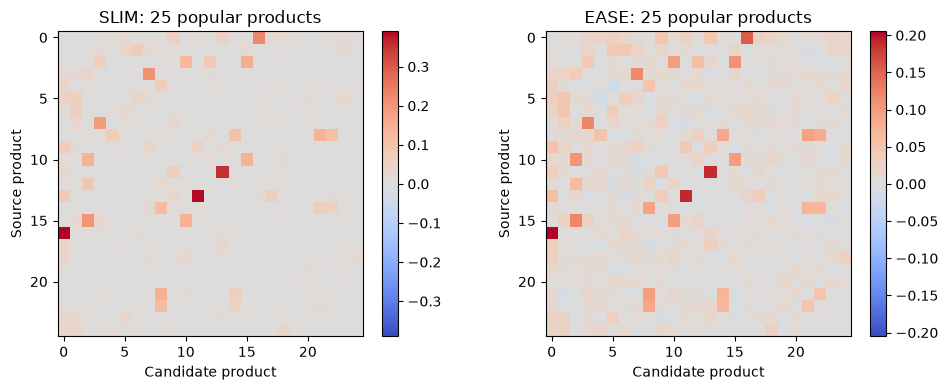

Heatmaps use the same products/order, but an independent color scale per model


In [16]:
slim_weights, ease_weights = models["SLIM"].W, models["EASE"].W
weight_report = pd.DataFrame([
    {"model": "SLIM", "nonzero_fraction": slim_weights.nnz / n_items ** 2,
     "negative_fraction": 0.0},
    {"model": "EASE", "nonzero_fraction": np.count_nonzero(ease_weights) / n_items ** 2,
     "negative_fraction": float((ease_weights < 0).mean())},
])
display(weight_report.round(4))
popular_ids = np.argsort(-np.asarray(X_final.sum(axis=0)).ravel())[:25]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, weights in [(axes[0], "SLIM", slim_weights[popular_ids][:, popular_ids].toarray()),
                          (axes[1], "EASE", ease_weights[np.ix_(popular_ids, popular_ids)])]:
    limit = max(float(np.max(np.abs(weights))), 1e-6)
    picture = ax.imshow(weights, cmap="coolwarm", vmin=-limit, vmax=limit)
    ax.set(title=name + ": 25 popular products", xlabel="Candidate product", ylabel="Source product")
    fig.colorbar(picture, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()
print("Heatmaps use the same products/order, but an independent color scale per model")


## 9. Recommendations and an additive explanation

Inspect one eligible October–November customer. Recommendations use the same seen-history exclusion and warm catalog as the metrics. For EASE, decompose the top product's score into source-product contributions $X_{ui}B_{ij}$. These are model explanations, not a claim of causal purchase influence.


In [17]:
example_user = int(test_details["Popularity"].user_idx.iloc[0])
all_seen_final = interaction_matrix(final_history, positive_only=False)
seen = all_seen_final.indices[all_seen_final.indptr[example_user]:all_seen_final.indptr[example_user + 1]]
candidate_mask = np.asarray(X_final.sum(axis=0)).ravel() > 0
print("Raw user ID:", int(user_ids[example_user]))
recent = final_history[final_history.user_idx == example_user].sort_values("timestamp").tail(5)
display(recent[["timestamp", "quantity", "item_idx"]].assign(
    title=lambda frame: products.title.to_numpy()[frame.item_idx])[["title", "quantity", "timestamp"]])
recommendation_rows = []
for name, model in models.items():
    with threadpool_limits(limits=1):
        scores = np.asarray(model.score_matrix())[example_user]
    top = top_items(scores, seen, candidate_mask, k=5)
    for rank, item in enumerate(top, start=1):
        recommendation_rows.append({"model": name, "rank": rank, "product": products.title.iloc[item],
                                    "score": scores[item]})
display(pd.DataFrame(recommendation_rows))

ease_scores = models["EASE"].score_matrix()[example_user]
target = int(top_items(ease_scores, seen, candidate_mask, k=1)[0])
sources = X_final.indices[X_final.indptr[example_user]:X_final.indptr[example_user + 1]]
contributions = ease_weights[sources, target]
assert np.isclose(contributions.sum(), ease_scores[target])
explanation = pd.DataFrame({"source_product": products.title.to_numpy()[sources],
                             "contribution": contributions}).sort_values("contribution", ascending=False)
print("EASE target:", products.title.iloc[target], "score:", round(ease_scores[target], 4))
display(explanation.head(5))
display(explanation.tail(5))


Raw user ID: 12347


,title,quantity,timestamp
575358,WOODLAND DESIGN COTTON TOTE BAG,6,2011-08-02 08:48:00
575357,WOODLAND CHARLOTTE BAG,10,2011-08-02 08:48:00
575377,60 TEATIME FAIRY CAKE CASES,24,2011-08-02 08:48:00
575366,REGENCY CAKESTAND 3 TIER,3,2011-08-02 08:48:00
575378,72 SWEETHEART FAIRY CAKE CASES,24,2011-08-02 08:48:00


,model,rank,product,score
0,Popularity,1,WHITE HANGING HEART T-LIGHT HOLDER,1398.000000
1,Popularity,2,PACK OF 72 RETROSPOT CAKE CASES,1031.000000
2,Popularity,3,BAKING SET 9 PIECE RETROSPOT,926.000000
3,Popularity,4,JUMBO BAG RED RETROSPOT,876.000000
4,Popularity,5,ASSORTED COLOUR BIRD ORNAMENT,870.000000
5,SLIM,1,ALARM CLOCK BAKELIKE IVORY,0.649872
6,SLIM,2,BLUE PARTY BAGS,0.594199
7,SLIM,3,PACK OF 60 PINK PAISLEY CAKE CASES,0.533422
8,SLIM,4,CHILDRENS CUTLERY POLKADOT GREEN,0.532219
9,SLIM,5,COSY SLIPPER SHOES SMALL RED,0.490931


EASE target: ALARM CLOCK BAKELIKE IVORY score: 0.3827


,source_product,contribution
56,ALARM CLOCK BAKELIKE RED,0.095044
57,ALARM CLOCK BAKELIKE PINK,0.086798
55,ALARM CLOCK BAKELIKE GREEN,0.073069
54,ALARM CLOCK BAKELIKE CHOCOLATE,0.061805
58,ALARM CLOCK BAKELIKE ORANGE,0.056630


,source_product,contribution
46,SET OF 2 TINS VINTAGE BATHROOM,-0.004322
20,COSY SLIPPER SHOES SMALL GREEN,-0.004845
44,MINI PAINT SET VINTAGE,-0.005519
9,HEART CALCULATOR,-0.006142
100,CHILDRENS CUTLERY RETROSPOT RED,-0.009251


## 10. Interpretation and extensions

Read the observed results rather than assuming a winner. SLIM trades sparse coefficients and interpretability for many elastic-net fits. EASE is solved directly but requires dense quadratic memory. FM shares latent interactions across feature combinations; the ID-only ablation and paired interval determine whether product text, price and country help in this run.

This is a real retailer's data, but results apply to **warm customers, the catalog observed in training and previously unpurchased products**. All eligible cleaned training history is included by default. Purchases may be for resale or gifts; customer intent and product availability are unobserved. Dropping return lines does not establish that every sale was retained. A binary history ignores quantity and repeat intensity. Global cutoffs prevent future events from entering training, but one split and one seed cannot establish general superiority.

The test period includes Christmas shopping season, so distribution shift is expected. Popularity is a strong reference; a lower training loss need not improve discovery. These offline metrics do not estimate conversion lift. Bootstrap intervals quantify differences across test customers, not robustness across seeds or future calendar periods.

**Extensions:** implement replenishment ranking that allows repeat purchases and compare with a customer-specific repeat-frequency baseline; use invoice sequences for next-basket prediction; compare binary and recency-weighted histories; ablate text/price/country separately; repeat seeds and calendar cutoffs; evaluate cold products from training-fitted text features without identity embeddings. For much larger catalogs, measure SLIM training cost and EASE's quadratic memory before selecting a computational strategy.

**References:** [UCI Online Retail II, Chen](https://doi.org/10.24432/C5CG6D), [SLIM, Ning & Karypis (2011)](https://doi.org/10.1109/ICDM.2011.134), [EASE, Steck (2019)](https://arxiv.org/abs/1905.03375), [FM, Rendle (2010)](https://doi.org/10.1109/ICDM.2010.127), [BPR, Rendle et al. (2009)](https://arxiv.org/abs/1205.2618).
